# Experiment: gradient-based refinement after the evolution

Evolutionary optimizers like `CMAES` and `Nuevolution` are good at finding the *region* of a good bore, but
slow at the last step: walking down to the bottom of the local minimum. A gradient-based optimizer is the
opposite. It cannot search globally, but near a minimum it knows exactly which way is down and how far to
go. The idea of this experiment: run the evolution first, then hand its best genome to a gradient-based
optimizer that pushes it to the nearest local minimum.

**Constraint:** no PyTorch (or any other autodiff framework), because of the size of the dependency. The
gradient therefore has to come from the existing simulation.

> **Now in the library:** the least-squares method of this experiment is available as `refine_least_squares` (and `refine_population(..., method="least-squares")`); see [least_squares_refinement.ipynb](least_squares_refinement.ipynb) for how to use it. This notebook keeps its own copy of the code as the record of the experiment.

Contents:

1. Setup
2. Is the loss differentiable? (smoothness and finite-difference accuracy)
3. Why the tuning loss needs a different formulation (kinks and residuals)
4. The three refinement methods
5. Experiment: 4 shapes x 3 targets x 3 seeds
6. Results
7. Conclusions and proposal for the library

## 1. Setup

`EVOLUTION_BUDGET` is the number of loss evaluations for the CMA-ES run that produces the start point,
`REFINE_BUDGET` the extra evaluations each refinement method gets afterwards.

In [1]:
import sys
sys.path.insert(0, "../../src")

import logging
import threading
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import least_squares, minimize
from scipy.signal import find_peaks

from didgelab import (
    CMAES,
    CompositeTairuaLoss,
    FrequencyTuningLoss,
    GeoGenomeA,
    HarmonicSplittingLoss,
    HighInharmonicLoss,
    IntegerHarmonicLoss,
    KigaliShape,
    ModalDensityLoss,
    NearIntegerLoss,
    PeakAmplitudeLoss,
    PeakQuantityLoss,
    QFactorLoss,
    ScaleTuningLoss,
    StretchedOddLoss,
)
from didgelab.acoustical_simulation import acoustical_simulation
from didgelab.app import init_app
from didgelab.shapes.MbeyaShape import MbeyaGenome

init_app("gradient_refinement", create_output_folder=False)
logging.disable(logging.WARNING)

EVOLUTION_BUDGET = 3000   # CMA-ES evaluations before the refinement starts
REFINE_BUDGET = 1000      # extra evaluations per refinement method
SEEDS = [1, 2, 3]
POOL = ThreadPoolExecutor(8)  # the simulation releases the GIL, so threads run in parallel

Shapes and targets as in the [optimizer benchmark](optimizer_benchmark.ipynb). The *Drone* only target is
left out (every optimizer solves it), *Full composite* is the eleven-component loss.

In [2]:
SHAPES = {
    "Kigali": lambda: KigaliShape(),
    "Kigali + bubbles": lambda: KigaliShape(n_bubbles=2),
    "Mbeya": lambda: MbeyaGenome(n_bubbles=2),
    "GeoGenomeA": lambda: GeoGenomeA.build(8),
}

TOOTS_HZ = np.array([73.4, 185.0, 293.7, 392.0])  # D2, F#3, D4, G4


def toots_loss():
    loss = CompositeTairuaLoss()
    loss.add_component("freq", FrequencyTuningLoss(np.log2(TOOTS_HZ), np.full(4, -1.0), [2.0, 1.0, 1.0, 0.5]))
    return loss


def scale_loss():
    loss = toots_loss()
    loss.add_component("scale", ScaleTuningLoss(62, [0, 3, 5, 7, 10], weight=2.0))  # D minor pentatonic
    loss.add_component("peaks_qty", PeakQuantityLoss(target_count=6, weight=1.0))
    return loss


def full_loss():
    targets = np.array([73.4, 146.8])
    loss = CompositeTairuaLoss()
    loss.add_component("freq", FrequencyTuningLoss(np.log2(targets), np.full(2, -1.0), [1.0, 1.0]))
    loss.add_component("scale", ScaleTuningLoss(60, [0, 2, 4, 5, 7, 9, 11], weight=5.0))
    loss.add_component("peaks_qty", PeakQuantityLoss(target_count=4, weight=2.0))
    loss.add_component("peaks_amp", PeakAmplitudeLoss(target_min_amplitude=0.25, weight=10.0))
    loss.add_component("q_factor", QFactorLoss(target_q=15.0, weight=1.0))
    loss.add_component("modal_density", ModalDensityLoss(cluster_range_cents=50.0, weight=1.0))
    loss.add_component("integer_harmonic", IntegerHarmonicLoss(weight=1.0))
    loss.add_component("near_integer", NearIntegerLoss(stretch_factor=1.002, weight=1.0))
    loss.add_component("stretched_odd", StretchedOddLoss(weight=1.0))
    loss.add_component("high_inharmonic", HighInharmonicLoss(weight=1.0))
    loss.add_component("harmonic_splitting", HarmonicSplittingLoss(harmonic_index=1, split_width_hz=5.0, weight=1.0))
    return loss


TARGETS = {"Drone + toots": toots_loss, "Scale": scale_loss, "Full composite": full_loss}

### Evaluating a genome

`analyze` does what `CompositeTairuaLoss.loss` does (coarse simulation, peak finding, peak refinement,
components), but also returns the refined peak frequencies, which the residual formulation in section 3 needs.
`Objective` wraps it for the optimizers: it takes a raw genome vector, counts every evaluation, stops with
`BudgetExhausted` when the budget is used up, and remembers the best genome seen.

In [3]:
def analyze(loss, shape):
    # Returns (component results incl. "total", refined peak frequencies in log2 Hz)
    geo = shape.genome2geo()
    grid = loss._freq_grid()
    impedances = np.asarray(acoustical_simulation(geo, grid))
    peak_indices, _ = find_peaks(impedances, prominence=0.05)
    peak_indices = peak_indices[grid[peak_indices] <= loss.fmax]
    if len(peak_indices) == 0:
        return {"total": 1e6}, np.array([])
    freqs_log, peak_imps, peak_qs = loss._refine_peaks(geo, grid, impedances, peak_indices)
    peak_impedances = peak_imps / (max(impedances.max(), peak_imps.max()) + 1e-9)
    results = {}
    for name, comp in loss.components.items():
        kwargs = {"peak_qs": peak_qs} if getattr(comp, "uses_peak_q", False) else {}
        results[name] = comp.calculate(freqs_log, peak_impedances, grid, impedances, peak_indices, **kwargs)
    results["total"] = sum(results.values())
    return results, freqs_log


class BudgetExhausted(Exception):
    pass


class Objective:
    def __init__(self, loss, template, budget):
        self.loss, self.template, self.budget = loss, template, budget
        self.lock = threading.Lock()
        self.n = 0
        self.best, self.best_x = np.inf, None
        self.curve = []
        self.n_peaks = None  # number of peak residuals, fixed at the start point

    def evaluate(self, x):
        with self.lock:
            if self.n >= self.budget:
                raise BudgetExhausted()
            self.n += 1
        shape = self.template.clone()
        shape.genome = np.clip(x, 0.0, 1.0)
        results, freqs_log = analyze(self.loss, shape)
        with self.lock:
            if results["total"] < self.best:
                self.best, self.best_x = results["total"], shape.genome.copy()
            self.curve.append(self.best)
        return results, freqs_log

    def total(self, x):
        return self.evaluate(x)[0]["total"]

    def residuals(self, x):
        return residual_vector(self.loss, *self.evaluate(x), self.n_peaks)


# analyze() must agree with the real loss
_shape = KigaliShape()
_loss = full_loss()
assert np.isclose(analyze(_loss, _shape)[0]["total"], _loss.loss(_shape)["total"])

## 2. Is the loss differentiable?

The loss is a long chain: genome → bore geometry → transmission-line simulation → peak finding → peak
refinement → loss components. Several steps contain `argmin`, `find_peaks` and absolute values, so it is not
obvious that a gradient exists. To find out, we take the best genome of a CMA-ES run, choose a random
direction $d$ and plot the loss along the line $x_0 + t\,d$ at four zoom levels.

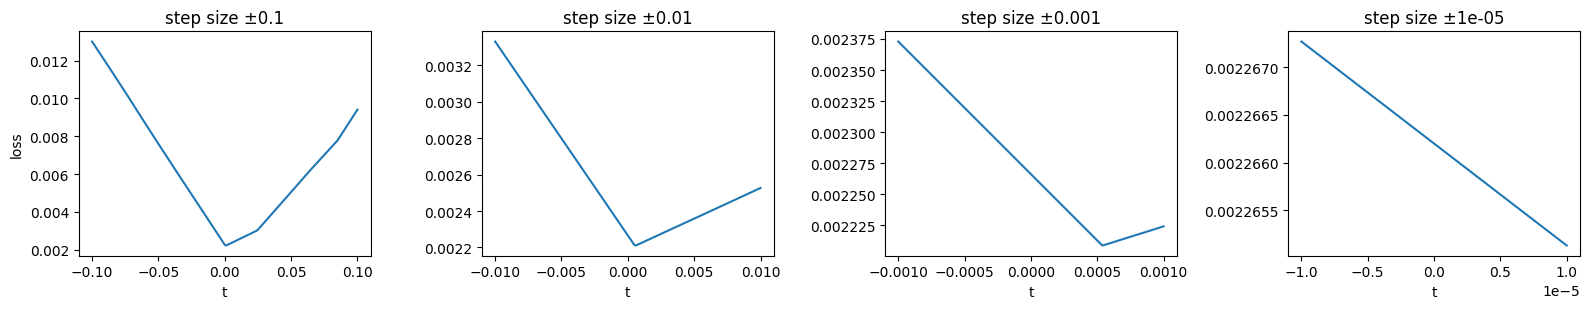

In [4]:
np.random.seed(1)
probe_loss = toots_loss()
probe_start = CMAES(probe_loss, KigaliShape(), num_generations=EVOLUTION_BUDGET // 16, population_size=16).evolve()[0]
probe = Objective(probe_loss, probe_start, budget=10**9)
x0 = probe_start.genome.copy()
direction = np.random.default_rng(0).standard_normal(len(x0))
direction /= np.linalg.norm(direction)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, h in zip(axes, [1e-1, 1e-2, 1e-3, 1e-5]):
    t = np.linspace(-h, h, 201)
    values = np.array(list(POOL.map(lambda s: probe.total(x0 + s * direction), t)))
    ax.plot(t, values)
    ax.set_title(f"step size ±{h:g}")
    ax.set_xlabel("t")
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.show()

The start point sits exactly in a **kink**: at every zoom level from ±0.1 down to ±0.001 the loss has the shape
of a "V" with its tip at (or next to) $t = 0$. This is the absolute value $|c|$ of section 3: CMA-ES has pushed
one of the peaks right onto its target, and a deviation in either direction costs the same. Away from the
tip, the loss is a smooth, almost straight line. At ±10⁻⁵ we see only one side of the V, a perfectly straight
line without any visible noise: the simulation is deterministic and the peak refinement interpolates, so there
is no grid noise.

That means **finite differences** give an accurate gradient (on either side of a kink). For each of the $n$
genes we evaluate the loss once more with that gene moved by a tiny step $\varepsilon$:

$$\frac{\partial L}{\partial x_i} \approx \frac{L(x + \varepsilon e_i) - L(x)}{\varepsilon}$$

This costs $n + 1$ evaluations per gradient (50 for the Kigali shape), but the evaluations are independent
and run in parallel threads, so a gradient takes about as long as a few sequential simulations. How small should
$\varepsilon$ be? The next cell compares the finite-difference gradient for different step sizes with a
reference (central differences at $\varepsilon = 10^{-6}$).

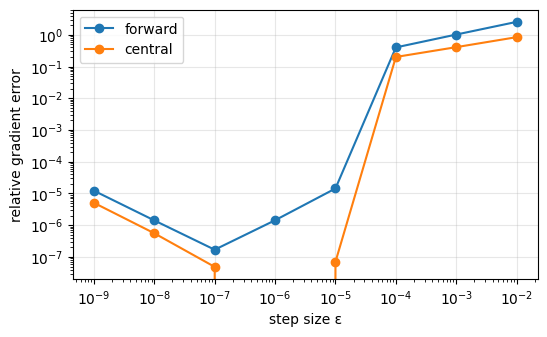

In [5]:
def fd_gradient(fun, x, eps, central=False):
    # Finite-difference gradient (or Jacobian, if fun returns a vector), evaluated in parallel
    steps = np.where(x + eps <= 1.0, eps, -eps)  # step inwards at the upper bound
    basis = np.eye(len(x))
    if central:
        plus = list(POOL.map(lambda i: fun(x + eps * basis[i]), range(len(x))))
        minus = list(POOL.map(lambda i: fun(x - eps * basis[i]), range(len(x))))
        return np.array([(p - m) / (2 * eps) for p, m in zip(plus, minus)]).T
    f0 = fun(x)
    shifted = list(POOL.map(lambda i: fun(x + steps[i] * basis[i]), range(len(x))))
    return np.array([(f - f0) / s for f, s in zip(shifted, steps)]).T


x_inner = np.clip(x0, 1e-3, 1 - 1e-3)  # keep central differences inside the box
reference = fd_gradient(probe.total, x_inner, 1e-6, central=True)
epsilons = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9]
errors = {kind: [np.linalg.norm(fd_gradient(probe.total, x_inner, e, central=kind == "central") - reference)
                 / np.linalg.norm(reference) for e in epsilons] for kind in ["forward", "central"]}
plt.figure(figsize=(6, 3.5))
for kind, err in errors.items():
    plt.loglog(epsilons, err, "o-", label=kind)
plt.xlabel("step size ε")
plt.ylabel("relative gradient error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Between $\varepsilon = 10^{-9}$ and $10^{-5}$ forward differences agree with the reference to better than
$10^{-4}$ (relative), at $10^{-7}$ even to $10^{-7}$. From $10^{-4}$ on the error jumps to 20-100%: the step
crosses the kink of the "V" above. Below $10^{-7}$ floating-point rounding slowly takes over. We use forward
differences with $\varepsilon = 10^{-6}$: half the cost of central differences and far more accurate than needed.

*Why not an exact gradient?* An analytic or automatic derivative of the transmission-line model would save the
factor $n$, but needs either PyTorch/JAX or a hand-written adjoint of the Cython kernel. With 17-55 genes and
parallel evaluation, finite differences cost a few milliseconds per gradient, so this is not worth it yet.

## 3. Kinks: why the tuning loss needs residuals

The frequency tuning loss is a sum of **absolute** deviations, $L = \sum_i w_i\, |c_i| / 600$ with $c_i$ the
deviation of peak $i$ from its target in cent. $|c|$ has a kink at $c = 0$: the gradient jumps from $-w$ to $+w$
exactly where we want to end up. A gradient method approaching the minimum keeps overshooting and has to take
smaller and smaller steps. The scale loss has the same kinks.

The fix is to hand the optimizer the **signed** deviations $r_i = w_i\, c_i / 600$ (the *residuals*) instead of
the sum of their absolute values, and minimize $\sum_i r_i^2$. This has the same minimum (all deviations zero)
but is smooth there. It is a nonlinear *least-squares* problem, and for those there are specialised methods
(Gauss-Newton, Levenberg-Marquardt) that use the Jacobian of the residuals and typically converge in a handful
of iterations.

`residual_vector` builds the residuals from the loss components:

* `FrequencyTuningLoss`: one residual per target, $w_i\, c_i / 600$ (signed cent deviation of the nearest peak).
* `ScaleTuningLoss`: one residual per peak, the signed cent distance to the nearest scale note, weighted like in
  the loss. The number of peaks is fixed at the start point, so the vector keeps its length.
* every other component: $\sqrt{L_k}$, so that its square is the component value again. This is generic but
  keeps whatever kinks the component has.

In [6]:
def residual_vector(loss, results, freqs_log, n_peaks):
    residuals = []
    for name, comp in loss.components.items():
        if isinstance(comp, FrequencyTuningLoss):
            for target, weight in zip(comp.target_freqs_log, comp.weights):
                nearest = freqs_log[np.argmin(np.abs(freqs_log - target))]
                residuals.append(weight * 1200 * (nearest - target) / 600)
        elif isinstance(comp, ScaleTuningLoss):
            for k in range(n_peaks):
                if k < len(freqs_log):
                    offsets = comp.scale_freqs_log - freqs_log[k]
                    nearest = offsets[np.argmin(np.abs(offsets))]
                    residuals.append(comp.weight / n_peaks * 1200 * nearest / 600)
                else:
                    residuals.append(0.0)
        else:
            residuals.append(np.sqrt(max(results[name], 0.0)))
    return np.array(residuals)

## 4. Refinement methods

All three start from the best genome of a CMA-ES run after `EVOLUTION_BUDGET` evaluations and get
`REFINE_BUDGET` more:

* **CMA-ES (continued)**: the baseline. The same CMA-ES run simply goes on for `REFINE_BUDGET` more
  evaluations. Its step size has already shrunk, so this is a fair local search too.
* **L-BFGS-B**: a quasi-Newton method from scipy on the total loss, with the finite-difference gradient and the
  bounds $[0, 1]$. It needs nothing but the loss, so it works for any loss, kinks included.
* **Least squares (TRF)**: scipy's `least_squares` with the trust-region-reflective method (a bounded
  Gauss-Newton / Levenberg-Marquardt variant) on the residuals of section 3, with the finite-difference
  Jacobian.

Each method stops when its budget is used up or when it has converged, whichever comes first.

In [7]:
FD_EPS = 1e-6


def refine_lbfgs(objective, x0):
    def fun_and_grad(x):
        f0 = objective.total(x)
        return f0, fd_gradient(objective.total, x, FD_EPS)
    try:
        minimize(fun_and_grad, x0, jac=True, method="L-BFGS-B", bounds=[(0.0, 1.0)] * len(x0),
                 options={"maxiter": 10**6, "maxfun": 10**6, "ftol": 1e-15, "gtol": 1e-12})
    except BudgetExhausted:
        pass


def refine_least_squares(objective, x0):
    objective.n_peaks = len(analyze(objective.loss, _with_genome(objective.template, x0))[1])
    try:
        least_squares(objective.residuals, x0, jac=lambda x: fd_gradient(objective.residuals, x, FD_EPS),
                      bounds=(0.0, 1.0), method="trf", x_scale="jac", ftol=1e-15, xtol=1e-15, gtol=1e-15,
                      max_nfev=10**6)
    except BudgetExhausted:
        pass


def _with_genome(template, x):
    shape = template.clone()
    shape.genome = np.clip(x, 0.0, 1.0)
    return shape


class TrackedLoss:
    # Counts the evaluations of the CMA-ES run and records its running best
    def __init__(self, loss):
        self.inner, self.lock, self.best, self.curve = loss, threading.Lock(), np.inf, []

    def loss(self, shape):
        if getattr(shape, "loss", None) is not None:
            return shape.loss
        result = self.inner.loss(shape)
        with self.lock:
            self.best = min(self.best, result["total"])
            self.curve.append(self.best)
        return result


def evolve_then_refine(make_loss, make_shape, seed):
    # CMA-ES for EVOLUTION_BUDGET + REFINE_BUDGET evaluations, snapshot after EVOLUTION_BUDGET
    np.random.seed(seed)
    tracked = TrackedLoss(make_loss())
    snapshot = {}

    def take_snapshot(i_generation, population):
        if "genome" not in snapshot and len(tracked.curve) >= EVOLUTION_BUDGET:
            snapshot["genome"] = population[0].clone()
            snapshot["evals"] = len(tracked.curve)

    total = EVOLUTION_BUDGET + REFINE_BUDGET
    CMAES(tracked, make_shape(), num_generations=total // 16, population_size=16,
          callback_generation_ended=take_snapshot).evolve()
    start = snapshot["genome"]
    start_loss = tracked.curve[snapshot["evals"] - 1]
    curves = {"CMA-ES (continued)": np.array(tracked.curve[snapshot["evals"]:snapshot["evals"] + REFINE_BUDGET])}
    finals = {"CMA-ES (continued)": curves["CMA-ES (continued)"][-1]}
    genomes = {"start": start.genome, "CMA-ES (continued)": None}
    seconds = {}
    for name, method in [("L-BFGS-B", refine_lbfgs), ("Least squares", refine_least_squares)]:
        objective = Objective(make_loss(), start, REFINE_BUDGET)
        t = time.time()
        method(objective, start.genome.copy())
        seconds[name] = time.time() - t
        curves[name] = np.minimum(np.array(objective.curve), start_loss)
        finals[name] = min(objective.best, start_loss)
        genomes[name] = objective.best_x if objective.best < start_loss else start.genome
    return start_loss, finals, curves, genomes, seconds

## 5. Experiment

Every combination of target, shape and seed: one CMA-ES run, then the two gradient methods from its snapshot.

In [8]:
rows, curves_all, genomes_all = [], {}, {}
t0 = time.time()
for target_name, make_loss in TARGETS.items():
    for shape_name, make_shape in SHAPES.items():
        for seed in SEEDS:
            start_loss, finals, curves, genomes, seconds = evolve_then_refine(make_loss, make_shape, seed)
            key = (target_name, shape_name, seed)
            curves_all[key], genomes_all[key] = curves, genomes
            row = {"target": target_name, "shape": shape_name, "seed": seed, "start": start_loss}
            row.update(finals)
            row.update({f"{name} evals": len(curves[name]) for name in ["L-BFGS-B", "Least squares"]})
            row.update({f"{name} s": s for name, s in seconds.items()})
            rows.append(row)
        print(f"{target_name:15s} {shape_name:17s} done after {time.time() - t0:5.0f} s")
results = pd.DataFrame(rows)
METHODS = ["CMA-ES (continued)", "L-BFGS-B", "Least squares"]

Drone + toots   Kigali            done after    27 s


Drone + toots   Kigali + bubbles  done after    66 s


Drone + toots   Mbeya             done after    83 s


Drone + toots   GeoGenomeA        done after    95 s


Scale           Kigali            done after   118 s


Scale           Kigali + bubbles  done after   153 s


... (2 outputs left out)

Full composite  Kigali            done after   208 s


Full composite  Kigali + bubbles  done after   236 s


Full composite  Mbeya             done after   246 s


Full composite  GeoGenomeA        done after   252 s


## 6. Results

### 6.1 Final loss

Mean loss over the seeds at the start point and after `REFINE_BUDGET` more evaluations with each method.
The last columns show how many evaluations the gradient methods actually used: they stop early when they
have converged.

In [9]:
table = results.groupby(["target", "shape"], sort=False)[["start"] + METHODS
                                                         + ["L-BFGS-B evals", "Least squares evals"]].mean()
fmt = {c: "{:.2e}" for c in ["start"] + METHODS}
fmt.update({"L-BFGS-B evals": "{:.0f}", "Least squares evals": "{:.0f}"})
table.style.format(fmt).highlight_min(subset=METHODS, axis=1, color="#c7e9c0")

Which method ended lowest, per target (one count per shape and seed):

In [10]:
winners = results[METHODS].idxmin(axis=1)
print(pd.crosstab(results["target"], winners).reindex(columns=METHODS, fill_value=0).loc[list(TARGETS)].to_string())

col_0           CMA-ES (continued)  L-BFGS-B  Least squares
target                                                     
Drone + toots                    0         0             12
Scale                            3         1              8
Full composite                  10         1              1


### 6.2 Loss during the refinement

Best loss against the number of extra evaluations, median over the seeds. One panel per target and shape.

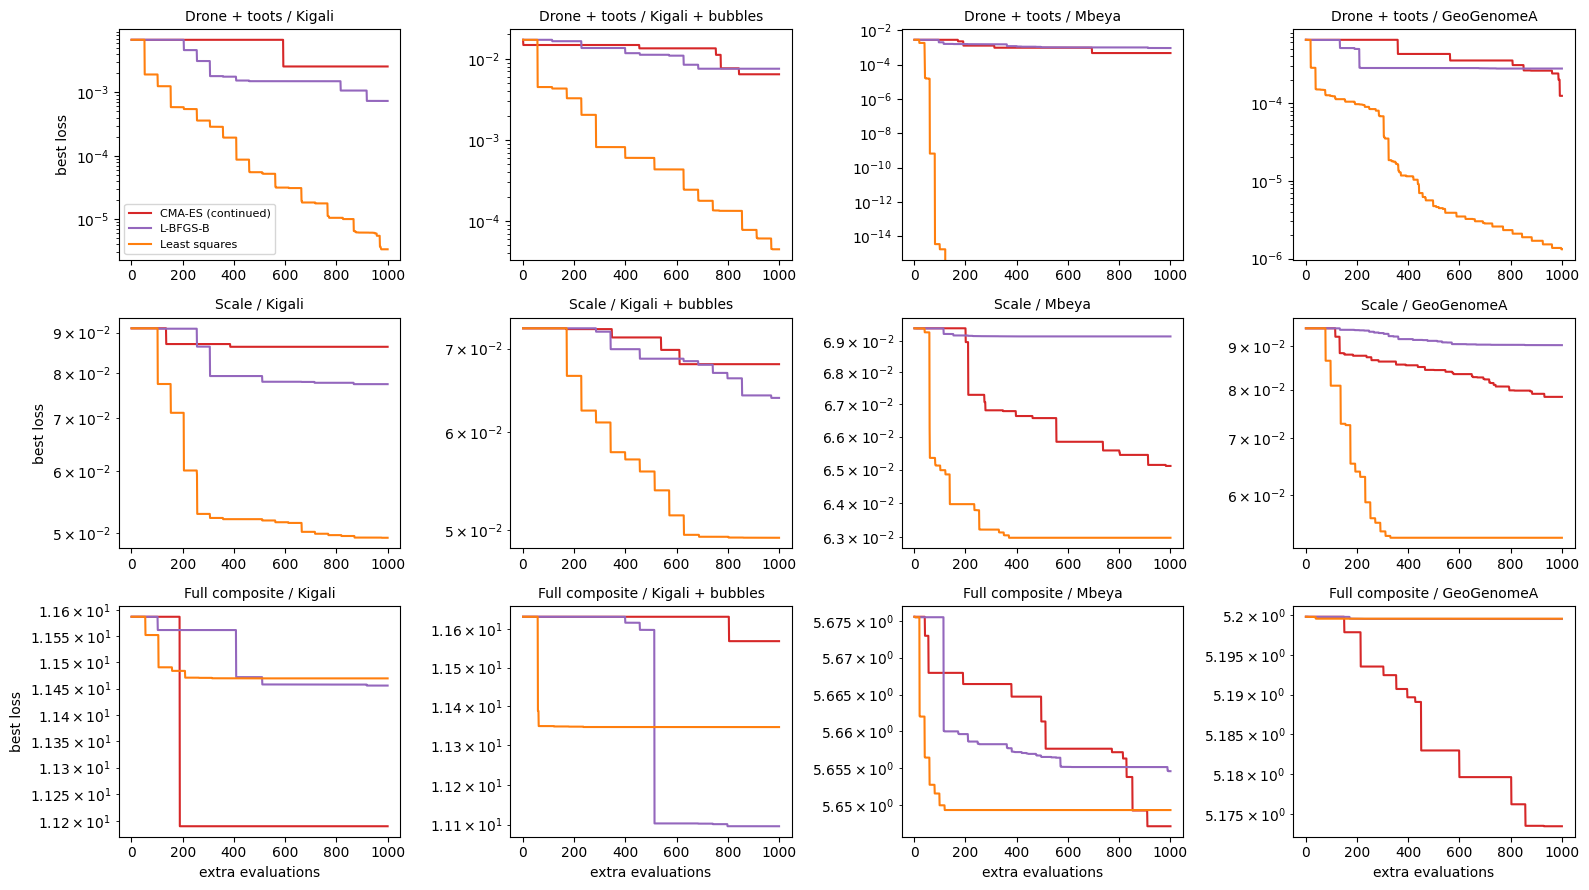

In [11]:
colors = {"CMA-ES (continued)": "tab:red", "L-BFGS-B": "tab:purple", "Least squares": "tab:orange"}
fig, axes = plt.subplots(len(TARGETS), len(SHAPES), figsize=(4 * len(SHAPES), 3 * len(TARGETS)), squeeze=False)
for i, target_name in enumerate(TARGETS):
    for j, shape_name in enumerate(SHAPES):
        ax = axes[i, j]
        for name in METHODS:
            padded = []
            for seed in SEEDS:
                c = curves_all[(target_name, shape_name, seed)][name]
                padded.append(np.concatenate([c, np.full(REFINE_BUDGET - len(c), c[-1])]) if len(c) else
                              np.full(REFINE_BUDGET, results.loc[(results["target"] == target_name)
                                                                 & (results["shape"] == shape_name)
                                                                 & (results["seed"] == seed), "start"].iloc[0]))
            ax.plot(np.arange(1, REFINE_BUDGET + 1), np.median(padded, axis=0), color=colors[name], label=name)
        ax.set_yscale("log")
        ax.set_title(f"{target_name} / {shape_name}", fontsize=10)
        if i == len(TARGETS) - 1:
            ax.set_xlabel("extra evaluations")
        if j == 0:
            ax.set_ylabel("best loss")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.3 In cent

A loss value is hard to interpret. For *Drone + toots* the table shows the worst deviation of the four target
peaks in cent, at the start point and after each method (median over the seeds).

In [12]:
def worst_cent(loss, template, genome):
    _, freqs_log = analyze(loss, _with_genome(template, genome))
    targets = np.log2(TOOTS_HZ)
    return max(abs(1200 * (freqs_log[np.argmin(np.abs(freqs_log - t))] - t)) for t in targets)


cent_rows = []
for shape_name, make_shape in SHAPES.items():
    row = {"shape": shape_name}
    for name in ["start", "L-BFGS-B", "Least squares"]:
        row[name] = np.median([worst_cent(toots_loss(), make_shape(), genomes_all[("Drone + toots", shape_name, s)][name])
                               for s in SEEDS])
    cent_rows.append(row)
pd.DataFrame(cent_rows).set_index("shape").style.format("{:.3f} cent")

,start,L-BFGS-B,Least squares
shape,,,
Kigali,1.539 cent,0.535 cent,0.002 cent
Kigali + bubbles,5.451 cent,3.924 cent,0.030 cent
Mbeya,1.014 cent,0.630 cent,0.000 cent
GeoGenomeA,0.192 cent,0.117 cent,0.001 cent


## 7. Conclusions

Results of the run above (CMA-ES for 3000 evaluations, then 1000 extra evaluations per method, 3 seeds):

* **Least squares on signed residuals is the method of choice for tuning targets.** On *Drone + toots* it ended
  lowest in all 12 runs. The worst target deviation drops from 0.2-5.5 cent after the evolution to
  0.000-0.03 cent (median per shape); L-BFGS-B leaves it at 0.1-3.9 cent. On the compact
  Mbeya shape it reaches an exact tuning after about 130 evaluations and stops. On *Scale* it won 8 of 12 runs
  and lowered the mean loss by 21-31% against the start, clearly more than the other two methods on every shape.
* **Plain gradient descent on the total loss (L-BFGS-B) does not work well.** It was the best method in only 2
  of 36 runs. The loss is a sum of absolute values; its minimum is a kink (section 2), and a gradient method that
  sees only the total loss keeps overshooting it. Reformulating the loss as residuals is what makes the
  difference, not the gradient alone.
* **For the full composite loss, gradients do not help.** Continuing CMA-ES won 10 of 12 runs, the gains of all
  methods are small (≤ 9%). Most of its eleven components are not smooth functions of the peaks (peak count,
  harmonic splitting, nearest-integer ratios, ...), and the generic $\sqrt{L_k}$ residuals keep their kinks.
  Gradient refinement only pays off for components that have a natural signed residual.
* **Cost:** a Jacobian costs $n + 1$ evaluations (18 for Mbeya, 50 for Kigali), run in parallel threads.
  No new dependency is needed: scipy's `least_squares` plus finite differences are enough, because the
  loss is smooth away from the kinks (section 2).

**Musical relevance.** After 3000 CMA-ES evaluations the targets are already within a few cent, and a deviation
of 0.01 cent is far below what anyone can hear or a didgeridoo maker can build. The real value is elsewhere:
the refinement takes the last step of the search in a few hundred evaluations, so the evolution could stop
earlier, and it reliably removes the remaining few-cent errors on hard targets (Kigali + bubbles: 5.5 → 0.03
cent). Whether stopping the evolution earlier and refining gives the same result faster was not tested here.

**Proposal for the library:**

1. Give `LossComponent` an optional `residuals(...)` method returning signed residuals, implemented for
   `FrequencyTuningLoss` and `ScaleTuningLoss` first. Others with a natural signed form
   (`IntegerHarmonicLoss`, `NearIntegerLoss`, `StretchedOddLoss`, `PeakAmplitudeLoss`) can follow.
2. Let `CompositeTairuaLoss` return the residual vector (and the refined peaks), instead of the `analyze` copy
   used in this notebook.
3. Add `refine_least_squares(loss, genome, max_evaluations)` to `didgelab.evo.local_search`: TRF least squares
   with a parallel finite-difference Jacobian, keeping the residual vector at a fixed length.
4. Use it at the end of the evolution on the best few genomes, when the loss has residual-capable components;
   otherwise keep the evolution running instead.